---
title: "Dr Doofenshmirtz: a trauma-defined yet well-adjusted genius? An Analysis with Informational Computing"
date: 2026-10-11
execute:
  enabled: false
---

In the animated series *Phineas and Ferb*, the character Dr. Heinz Doofenshmirtz (Doof) is a comic villain with an unusual combination of traits. Defined by his absurdly tragic backstories, Doof is a chaotic mix of a brilliant (albeit ignorant) inventor, an insecure midlifer, and an unexpectly doting father. 

This leads me toward a strange conjecture: **Dr Doofenshmirtz is a tortured genius who is also well-adjusted**. 

Naturally, I have no choice but to climb onboard this train of thought and see where it takes me.

In the analysis below, I will explore the validity of this claim by breaking down its exact meaning and structure. Then, I will use the informational programming language `Lana` to review what evidence from the show supports or contradicts the conjecture, and also what counts as evidence to begin with. 

`Python` is still used for file checks and display.

## 1. Semantic Formalization

I have derived 3 claims made in the conjecture about Doof as such:

1. `Genius`

2. `Tortured`

3. `Well-adjusted`

Next, I will formalize each of these claims using this template:

*Claim = Semantic Component 1 + ... + Semantic Component X*

***NOTE: These definitions are conceptual models made for the scope of this analysis.*** *It is neither representative of the claims' total semantical capacity nor an equation meant literally.*

---

*Genius = Technical Competence + Originality + Technical Insight*

where:

- Technical Competence = the ability to apply knowledge/skills to solve problems effectively

- Originality = the ability to produce ideas that are meaningfully distinct from what already exists

- Technical Insight = the ability to recognize underlying relationships and assumptions within systems that are not immediately apparent

---

*Tortured = Psychological Distress + Perceived Inescapability*

where:

- Psychological Distress = the intensity of mental or emotional suffering, expressed in words or behavior

- Perceived Inescapability = the sense that one's suffering cannot be resolved or escaped

---

*Well-Adjusted = Emotional Regulation + Psychological Flexibility*

where:

- Emotional Regulation = the ability to experience and manage emotions without being overwhelmed or controlled by them

- Psychological Flexibility = the ability to adapt one's thoughts, behaviors, and expectations to changing circumstances

---

## 2. Establishing Indicators

The seven definitions above are mapped to the three claims in [the Lana analysis](doofenshmirtz-corpus/analyze_evidence.lana). The codebook is shown below after the saved evidence is checked.

## 3. Evidence Dataset

Episode transcripts are the dataset I will be using for further analysis. They are imported from a public source: https://github.com/captainsidd/phineas-ferb/.

Next, the dataset is reviewed in 3 stages:

1. **Full-inventory AI screening:** - `gemma4:31b` reads each usable transcript and proposed passages relevant to the seven indicators. 

2. **AI Passage review:** - `GPT-6 Astra` then reads the selected passages in their original context and checks whether the interpretation fits.

3. **Human review:** Read the cited passages and record separate decisions to verify AI-reviewed oberservations. I did not load any separate decisions into the table; the verification passed.

The code below checks the saved files. The next cell sends checked rows to Lana for classification and counts; Python displays the result.

In [1]:
import json
import os
import shutil
import subprocess
import tempfile
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_nb_file = globals().get("__vsc_ipynb_file__")
_nb_dir = Path(_nb_file).resolve().parent if _nb_file else Path.cwd()
CORPUS_ROOT = _nb_dir / "doofenshmirtz-corpus"
if not (CORPUS_ROOT / "github-transcripts/raw").is_dir():
    PROJECT_ROOT = _nb_dir if (_nb_dir / "_quarto.yml").is_file() else _nb_dir.parent
    CORPUS_ROOT = PROJECT_ROOT / "drafts/doofenshmirtz-corpus"

assert (CORPUS_ROOT / "github-transcripts/raw").is_dir(), "Source validation requires the local doofenshmirtz-corpus snapshot described in website/doofenshmirtz-corpus/README.md"

manifest = pd.read_csv(CORPUS_ROOT / "episode_manifest.csv")
evidence = pd.read_csv(CORPUS_ROOT / "reviewed_evidence.csv")
conclusions = pd.read_csv(CORPUS_ROOT / "claim_conclusions.csv")
required_manifest = {"episode_id", "season", "title", "source_path", "review_state"}
required_evidence = {
    "evidence_id", "episode_id", "scene_id", "source_file", "start_line", "end_line",
    "source_sha256", "observation", "indicator", "polarity", "confidence",
    "reviewer_note", "reviewer", "review_state",
}
assert required_manifest <= set(manifest.columns), "Missing manifest columns"
assert required_evidence <= set(evidence.columns), "Missing evidence columns"
assert not evidence.empty, "No scene observations are recorded"
assert evidence[list(required_evidence)].notna().all().all(), "Incomplete evidence row"
assert manifest["episode_id"].is_unique and evidence["evidence_id"].is_unique
assert set(manifest["review_state"]) <= {"full_text_ai_screened", "placeholder", "duplicate", "out_of_scope_movie", "missing"}
reviewed = manifest.loc[manifest["evidence_passages_checked"].eq("yes")]
assert reviewed["review_state"].eq("full_text_ai_screened").all()
import json
for row in manifest.loc[manifest["source_path"].notna()].itertuples():
    assert sha256((CORPUS_ROOT / row.source_path).read_bytes()).hexdigest() == row.source_sha256
    record = json.loads((CORPUS_ROOT / row.screening_record).read_text())
    assert record["source_sha256"] == row.source_sha256 and record["status"] == row.review_state
screened = manifest.loc[manifest["review_state"].eq("full_text_ai_screened")]
assert len(screened) == 211 and screened["reference_id"].nunique() == 210
assert set(evidence["episode_id"]) == set(reviewed["episode_id"])
assert set(evidence["confidence"]) <= {"high", "medium", "low"}
assert evidence["review_state"].eq("accepted").all()
source_paths = reviewed.set_index("episode_id")["source_path"]
for row in evidence.itertuples():
    assert row.source_file == source_paths.loc[row.episode_id], row.evidence_id
    source = (CORPUS_ROOT / row.source_file).read_bytes()
    assert sha256(source).hexdigest() == row.source_sha256, f"Source changed: {row.source_file}"
    assert int(row.start_line) == row.start_line and int(row.end_line) == row.end_line
    assert 1 <= row.start_line <= row.end_line <= len(source.decode().splitlines()), row.evidence_id
assert {"claim", "finding", "evidence_ids", "uncertainty", "reviewer"} <= set(conclusions.columns)
assert conclusions["claim"].is_unique
for refs in conclusions["evidence_ids"]:
    assert set(refs.split(";")) <= set(evidence["evidence_id"]), "Unknown conclusion reference"


Only transcripts for 210 out of the 222 titles across Seasons 1-4 were available at source; *I am accepting the ~95% reconciliation rate as a pass.*

Next, let's have the code analyze the evidence and then chart the saved observations for our readability.

Lana 4.0.0 analyzed 51 source-checked observations from 17 transcript files.
Screened 211 usable files covering 210 reference titles.


,claim,semantic_component
0,GENIUS,technical_competence
1,GENIUS,originality
2,GENIUS,technical_insight
3,TORTURED,psychological_distress
4,TORTURED,perceived_inescapability
5,WELL_ADJUSTED,emotional_regulation
6,WELL_ADJUSTED,psychological_flexibility


,files_screened,files_with_checked_evidence,titles_screened
season,,,
1,39,1,39
2,64,3,64
3,60,6,59
4,48,7,48



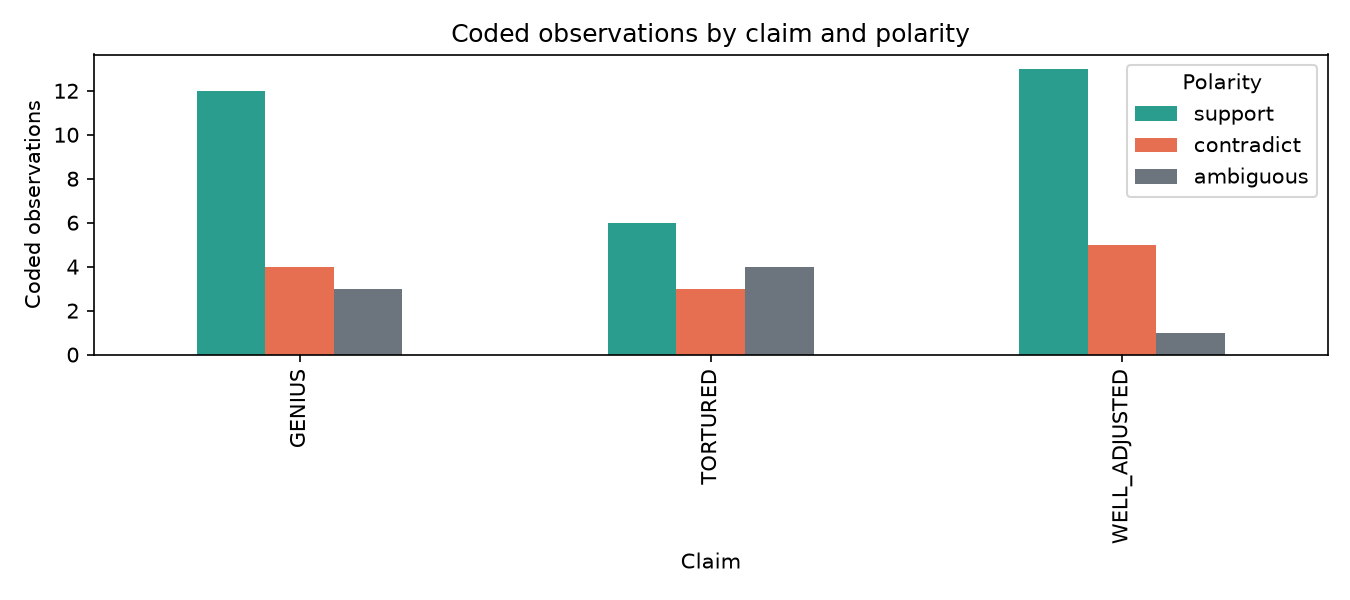

In [2]:
lana_source = CORPUS_ROOT / "analyze_evidence.lana"
lana_bin = os.environ.get("LANA_BIN") or shutil.which("lana") or str(CORPUS_ROOT.parents[2] / "lana" / "build" / "lana")
assert Path(lana_bin).is_file(), "Lana executable not found; set LANA_BIN"
assert subprocess.run([lana_bin, "version"], capture_output=True, text=True, check=True).stdout.startswith("Lana 4.0.0"), "This analysis requires Lana 4.0.0"
payload = {
    "observations": evidence[["evidence_id", "indicator", "polarity"]].to_dict("records"),
    "manifest": manifest[["season", "reference_id", "review_state", "evidence_passages_checked"]].fillna("").to_dict("records"),
}
with tempfile.TemporaryDirectory() as temp:
    input_path = Path(temp) / "reviewed-input.json"
    program_path = Path(temp) / "analyze_evidence.labc"
    input_path.write_text(json.dumps(payload, allow_nan=False), encoding="utf-8")
    subprocess.run([lana_bin, "compile", str(lana_source), "-o", str(program_path)], check=True)
    result = subprocess.run([lana_bin, "run", str(program_path), "--", str(input_path)], check=True, capture_output=True, text=True)
    lana_result = json.loads(result.stdout)

classifications = pd.DataFrame(lana_result["classifications"])
assert len(classifications) == len(evidence)
assert classifications["evidence_id"].is_unique
assert set(classifications["evidence_id"]) == set(evidence["evidence_id"])
assert classifications["provenance_operation"].eq("evidence").all()
assert set(conclusions["claim"]) == set(row["claim"] for row in lana_result["ledger"])
evidence = evidence.merge(classifications[["evidence_id", "claim"]], on="evidence_id", validate="one_to_one")
codebook = pd.DataFrame(lana_result["codebook"])
coverage = pd.DataFrame(lana_result["coverage"]).set_index("season")
ledger = pd.DataFrame(lana_result["ledger"]).set_index("claim")[["support", "contradict", "ambiguous"]]
indicator_ledger = pd.DataFrame(lana_result["indicator_ledger"]).set_index("indicator")[["support", "contradict", "ambiguous"]]
assert int(ledger.to_numpy().sum()) == len(evidence)
assert lana_result["screened_files"] == 211 and lana_result["checked_files"] == 17
print(f"Lana 4.0.0 analyzed {len(evidence)} source-checked observations from {lana_result['checked_files']} transcript files.")
print(f"Screened {lana_result['screened_files']} usable files covering {int(coverage['titles_screened'].sum())} reference titles.")
display(codebook)
display(coverage)

from base64 import b64encode
from io import BytesIO
from IPython.display import HTML

figure, axes = plt.subplots(figsize=(9, 4))
ledger.plot.bar(
    ax=axes,
    color={"support": "#2a9d8f", "contradict": "#e76f51", "ambiguous": "#6c757d"},
    title="Coded observations by claim and polarity",
)
axes.set_xlabel("Claim")
axes.set_ylabel("Coded observations")
axes.legend(title="Polarity")
figure.tight_layout()
image = BytesIO()
figure.savefig(image, format="png", dpi=150)
chart = b64encode(image.getvalue()).decode("ascii")
display(HTML(f'<img src="data:image/png;base64,{chart}" alt="Coded observation counts by claim and polarity; values are provided in the preceding table." style="max-width:100%;height:auto">'))
plt.close(figure)

## 4. Observation Counts by Claim

[The Lana program](doofenshmirtz-corpus/analyze_evidence.lana) tags each saved observation as evidence, maps its indicator to one claim, and groups the observations by claim and polarity. The table below shows the indicator mapping and the output.

In [3]:
display(indicator_ledger)
display(ledger)

,support,contradict,ambiguous
indicator,,,
technical_competence,9,1,0
originality,0,1,3
technical_insight,3,2,0
psychological_distress,5,0,1
perceived_inescapability,1,3,3
emotional_regulation,3,2,0
psychological_flexibility,10,3,1


,support,contradict,ambiguous
claim,,,
GENIUS,12,4,3
TORTURED,6,3,4
WELL_ADJUSTED,13,5,1


A fascinating mix of results here. 

1. `GENIUS` has 12 supporting observations, but the indicator table above has **no supporting observation for originality**. 
2. `TORTURED` has six supporting observations, mostly for distress; evidence about feeling unable to escape is mixed. 
3. `WELL_ADJUSTED` has 13 supporting observations, especially for flexibility, alongside five contradictions.

## 5. Conclusion

According to the evidence, Doof is good at building things, less so good at inventing *new* things, and very good at carrying pain. 

Yet, he is not stuck there forever: throughout the seasons, he changes his mind, accepts help, and even learns to handles disappointment well. 

So “tortured, well-adjusted genius” needs a tune-up; he is a capable, hurting inventor learning to adjust. No Feelings-Fix-inator required.

## Appendix

### Scope and Limits

AI can miss scenes, confuse speakers, or misread dreams and alternate stories. Transcripts were not compared to videos.

The 51 observations are selected examples. One passage can support more than one indicator. Repeated clips and time loops can also produce related observations. As a result, the counts do not show how often Doof behaves this way.

### Reviewed Evidence

Expand a claim to read its saved observations, interpretation notes, and transcript links.

In [4]:
from html import escape
from IPython.display import HTML

titles = manifest.set_index("episode_id")["title"]
for claim in ledger.index:
    rows = evidence.loc[evidence["claim"].eq(claim)]
    parts = [f"<details><summary><strong>{escape(claim.replace('_', ' ').title())}</strong> — {len(rows)} observations</summary>"]
    for row in rows.itertuples():
        source_link = (
            "https://github.com/captainsidd/phineas-ferb/blob/"
            "b49d21b85f5ae0725a68d414b62f34b069330239/"
            f"{row.source_file.removeprefix('github-transcripts/raw/')}"
            f"#L{row.start_line}-L{row.end_line}"
        )
        parts.append(
            f"<p><strong>{escape(row.evidence_id)} — {escape(titles.loc[row.episode_id])}</strong> · "
            f"{escape(row.indicator.replace('_', ' '))} · {escape(row.polarity)} · "
            f"confidence: {escape(row.confidence)}<br>"
            f"{escape(row.observation)}<br>"
            f"<em>Interpretation:</em> {escape(row.reviewer_note)}<br>"
            f"<a href=\"{escape(source_link, quote=True)}\">Source transcript</a>, "
            f"lines {row.start_line}–{row.end_line}.</p>"
        )
    parts.append("</details>")
    display(HTML("\n".join(parts)))
